# Cohort, duration and Aalen-Johansen estimators on CEREP

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (cohorts, the one-year PD and the long-run average)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- pool the annual cohort tables into one matrix with Anderson and Goodman's estimator and put three intervals (Wald, Agresti-Coull, Jeffreys) on a thin grade's PD;
- say what the cohort estimator cannot see (what happens inside the year) and what the duration estimator uses instead (every jump and the time spent in each grade);
- compute a duration generator, an Aalen-Johansen matrix and an EM generator on a rating-path dataset whose true generator is known, and read each against the truth;
- explain, with every intermediate printed, why the duration estimator gives a non-zero PD to a grade where the cohort estimator saw no default;
- read the committed 200-draw evidence of how often each estimator returns exactly zero and how large its error is.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import embedding, estimators, intervals
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files of case C04, all derived from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: the S&P annual cohorts (26 tables, 2000 to 2025), the pooled matrix and the generators.
- `data/derived/C04/fitch.json`: the same for Fitch (24 annual cohorts), for a comparison across agencies.
- `data/derived/C04/models-transitions.json`: the generator the case fitted to S&P's counts by EM (`fit.generator.q`) and the number of obligors it simulates from (`fit.generator.obligors`). This generator is the **known truth** of the second half of the notebook.
- `data/derived/C04/markov.json`: the committed simulation study, 200 seeded datasets drawn from that generator, with the bias and the error of six estimators.

CEREP publishes snapshots (the ratings on 1 January and on 31 December), never individual rating paths, so the continuous-time estimators cannot be run on the real tables: they need the date of every jump. That is why the notebook draws **one** dataset of rating paths from the committed generator with the engine's `RatingPaths`: it is small (a fraction of a second), seeded, and every estimator can be compared with the generator that made it.

The next cell loads the files and prints what they hold.

In [2]:
# Load the four artifacts (the notebook sits three folders below the repository root) and print what they hold
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
fitch = json.loads((C04 / "fitch.json").read_text(encoding="utf-8"))
models = json.loads((C04 / "models-transitions.json").read_text(encoding="utf-8"))
markov = json.loads((C04 / "markov.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]

for label, doc in (("sp", sp), ("fitch", fitch), ("models-transitions", models), ("markov", markov)):
    print(f"{label:20s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("S&P annual cohorts:", len(out["cohorts"]), "| Fitch:", len(fitch["outputs"]["cohorts"]))
print("obligors the truth generator simulates, by grade:", models["fit"]["generator"]["obligors"])
print("simulation study: draws:", markov["outputs"]["design"]["reps"], "| years:", markov["outputs"]["design"]["years"])

sp                   baked by riskvalidation 0.4.3 | installed 0.8.1
fitch                baked by riskvalidation 0.4.3 | installed 0.8.1
models-transitions   baked by riskvalidation 0.4.3 | installed 0.8.1
markov               baked by riskvalidation 0.4.3 | installed 0.8.1
S&P annual cohorts: 26 | Fitch: 24
obligors the truth generator simulates, by grade: [75, 822, 1814, 1756, 1054, 1391, 201]
simulation study: draws: 200 | years: 5


## Method

### Step 1: pooling the annual cohorts

One cohort gives each grade a few hundred ratings, and a rare transition may not appear in it. Anderson and Goodman (1957, equation 2.8) pool the periods under time homogeneity: add the corresponding entries of the count tables and divide each row by its total,

$$\hat p_{ij} = \frac{\sum_t N_{ij}(t)}{\sum_t \sum_k N_{ik}(t)}$$

Each year's withdrawn ratings are removed first (the industry treatment of notebook 01). Years with more ratings weigh more, which is why the pooled rate is not the average of the yearly rates of notebook 01. The next cell calls the engine's `pooled_cohort` on the 26 tables and checks the result: rows sum to one, no entry is negative, and it equals the pooled matrix the artifact commits.

In [3]:
# Pool the 26 annual tables with the engine and check the matrix against the committed one
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["cohorts"]]
withdrawn = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in out["cohorts"]]
pooled = estimators.pooled_cohort(tables, withdrawn, treatment="exclude")
p_pooled = pooled["matrix"]

print("periods pooled:", pooled["periods"], "| rows without ratings:", pooled["empty_rows"])
print("rows sum to one:", bool(np.allclose(p_pooled.sum(axis=1), 1.0)), "| no negative entry:", bool(np.all(p_pooled >= 0)))
print("largest difference to the committed matrix:", float(np.abs(p_pooled - np.array(out["pooled"]["matrix"])).max()))
print(f"{'grade':8s}{'ratings pooled':>30s}{'defaults':>16s}{'pooled PD':>14s}")
for g in range(7):
    print(f"{grades[g]:8s}{pooled['row_sizes'][g]:30.0f}{pooled['counts'][g, -1]:16.0f}{p_pooled[g, -1]:14.6f}")

periods pooled: 26 | rows without ratings: []
rows sum to one: True | no negative entry: True
largest difference to the committed matrix: 0.0
grade                   ratings pooled        defaults     pooled PD
AAA                               1895               0      0.000000
AA                               20192               1      0.000050
A                                45073              13      0.000288
BBB                              42854              35      0.000817
BB                               24842              86      0.003462
B                                31712             372      0.011731
CCC-C                             3731             301      0.080675


### Step 2: an interval on a thin grade

The pooled PD of AA rests on one default in about twenty thousand ratings, and AAA's on none. A point estimate says nothing of that. The engine offers three intervals at 95%, all in `transitions.intervals`: the Wald interval $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$, the Agresti-Coull interval, which adds $z^2$ pseudo-observations before applying the Wald formula, and the equal-tailed Jeffreys interval, the quantiles $\mathrm{Beta}(D + \tfrac12,\, n - D + \tfrac12)$ (Brown, Cai and DasGupta, 2001). Schuermann and Hanson (2004) use the first two for PDs by grade. The next cell calls the three on the pooled counts and checks them against the intervals the artifact commits for the same definition.

In [4]:
# Call the three interval methods on the pooled defaults and ratings, and compare with the committed intervals
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]
committed = out["lra"]["d4"]
print(f"{'grade':8s}{'Wald':>26s}{'Agresti-Coull':>26s}{'Jeffreys':>26s}")
agree = True
for name, fn in (("wald", intervals.pd_wald), ("agresti_coull", intervals.pd_agresti_coull), ("jeffreys", intervals.pd_jeffreys)):
    result = fn(defaults, ratings, level=0.95)
    agree &= bool(np.allclose(result["lower"], committed[name]["lower"], atol=1e-8) and np.allclose(result["upper"], committed[name]["upper"], atol=1e-8))
    if name == "wald":
        wald, ac, jef = result, None, None
    elif name == "agresti_coull":
        ac = result
    else:
        jef = result
for g in range(7):
    row = "".join(f"{r['lower'][g]:12.5f} to {r['upper'][g]:.5f}"[:26].rjust(26) for r in (wald, ac, jef))
    print(f"{grades[g]:8s}{row}")
print("equal to the committed intervals:", agree)
print("AAA: observed defaults:", int(defaults[0]), "| Wald length:", wald["length"][0], "| Jeffreys upper bound:", round(float(jef["upper"][0]), 5))

grade                         Wald             Agresti-Coull                  Jeffreys
AAA             0.00000 to 0.00000        0.00000 to 0.00244        0.00000 to 0.00132
AA              0.00000 to 0.00015        0.00000 to 0.00031        0.00001 to 0.00023
A               0.00013 to 0.00045        0.00016 to 0.00050        0.00016 to 0.00048
BBB             0.00055 to 0.00109        0.00058 to 0.00114        0.00058 to 0.00112
BB              0.00273 to 0.00419        0.00280 to 0.00428        0.00279 to 0.00425
B               0.01055 to 0.01292        0.01060 to 0.01298        0.01059 to 0.01296
CCC-C           0.07194 to 0.08941        0.07235 to 0.08986        0.07226 to 0.08974
equal to the committed intervals: True
AAA: observed defaults: 0 | Wald length: 0.0 | Jeffreys upper bound: 0.00132


A grade with no observed default gets a Wald interval of width zero: the estimator is certain of a PD that rests on nothing. The other two keep an upper bound. Notebook 10 measures how often each interval contains the truth when a grade is thin.

### Step 3: a dataset whose truth is known

The generator the case fitted to S&P's counts is the truth here. The next cell reads it from `models-transitions.json`, checks that it is a valid generator (non-negative off-diagonal entries, rows summing to zero, default absorbing) and computes its one-year PD by grade, $\exp(Q)$'s default column. Then `RatingPaths` draws, with a seeded random stream, the rating path of every obligor over five years, observed at annual snapshots like CEREP. The draw is exact: the engine simulates the continuous-time chain, so the paths hold the date of every jump, which a real CEREP table does not.

In [5]:
# Read the truth generator, check it, and draw one seeded dataset of rating paths observed at annual snapshots
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
pd_true = expm(q_true)[:7, -1]

print("valid generator:", embedding.is_generator(q_true))
print("mean time in each grade before leaving (years):", np.round(-1.0 / np.diag(q_true)[:7], 2))

generator = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
data = generator.draw(np.random.default_rng(20261021))
segments, steps = data["segments"], data["steps"]
print("obligors:", int(sum(n_obligors)), "| segments (one per stay in a grade):", len(segments["obligor"]), "| annual snapshot tables:", len(steps))
print(f"{'grade':8s}{'true one-year PD':>26s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:26.6f}")

valid generator: True
mean time in each grade before leaving (years): [ 5.12  8.51 15.69 13.36  7.22  6.59  2.89]
obligors: 7113 | segments (one per stay in a grade): 10953 | annual snapshot tables: 5
grade             true one-year PD
AAA                       0.000066
AA                        0.000049
A                         0.000288
BBB                       0.000817
BB                        0.003462
B                         0.011731
CCC-C                     0.080618


### Step 4: the cohort estimator against the duration estimator

On the same obligors, two readings. The cohort estimator sees only the five annual snapshots: it pools them with equation 2.8 and reads the default column. The duration estimator (Lando and Skodeberg, 2002) uses every jump and the time each obligor spent in each grade. For a time-homogeneous chain observed continuously the likelihood is maximised by

$$\hat q_{ij} = \frac{K_{ij}}{S_i}, \quad i \neq j, \qquad \hat q_{ii} = -\sum_{j \neq i} \hat q_{ij}$$

with $K_{ij}$ the number of observed jumps from $i$ to $j$ and $S_i$ the total time spent in $i$; the one-year matrix is $P = \exp(\hat Q)$. A rating can go AAA to AA to A to ... to default inside one year, and the duration estimator sees every step, while a snapshot sees only the beginning and the end. The next cell prints the jumps and the holding times, checks the generator, and puts the two PDs beside the truth.

In [6]:
# The duration generator from the paths (K_ij / S_i) and the pooled cohort estimator from the annual snapshots, beside the truth
dur = estimators.duration_generator(segments, len(states))
q_dur = dur["generator"]
jumps, holding = np.array(dur["jumps"]), np.array(dur["holding"])
print("jumps K from grade AAA (to AAA..D):", jumps[0].astype(int))
print("time S spent in each grade (obligor-years):", np.round(holding[:7], 1))
print("first row of Q is K / S:", bool(np.allclose(q_dur[0, 1:], jumps[0, 1:] / holding[0])))
print("valid generator:", embedding.is_generator(q_dur), "| states never left:", dur["unobserved"])

cohort_5 = estimators.pooled_cohort([s["counts"] for s in steps])
pd_cohort = cohort_5["matrix"][:7, -1]
pd_dur = expm(q_dur)[:7, -1]
print(f"{'grade':8s}{'truth':>12s}{'cohort':>12s}{'duration':>12s}{'defaults seen at snapshots':>46s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{pd_cohort[g]:12.6f}{pd_dur[g]:12.6f}{cohort_5['counts'][g, -1]:46.0f}")

jumps K from grade AAA (to AAA..D): [ 0 54  0  0  0  1  1  0]
time S spent in each grade (obligor-years): [ 240.2 3674.1 9263.6 8977.5 5090.  6432.9 1313.1]
first row of Q is K / S: True
valid generator: True | states never left: []
grade          truth      cohort    duration                    defaults seen at snapshots
AAA         0.000066    0.000000    0.000204                                             0
AA          0.000049    0.000000    0.000013                                             0
A           0.000288    0.000217    0.000257                                             2
BBB         0.000817    0.000895    0.000932                                             8
BB          0.003462    0.004480    0.004808                                            23
B           0.011731    0.013231    0.012517                                            86
CCC-C       0.080618    0.087678    0.089439                                           111


Neither estimator saw an AAA default: the jump count `K` of the AAA row to default is zero. The cohort estimator therefore reads exactly zero. The duration estimator did see AAA obligors jump to B and to CCC-C inside the year, and the matrix exponential chains those jumps with the default rates of B and CCC-C, so it returns a positive PD. One draw is one sample, so the duration number can sit above or below the truth (here above for AAA, below for AA); step 7 reads what 200 draws say about the size of the error.

### Step 5: Aalen-Johansen, without time homogeneity

The duration estimator assumes one generator for the whole period. Aalen and Johansen (1978) drop that: they estimate the transition matrix between any two dates $s < t$ as the product, over the observed jump times $u$ in $(s, t]$, of the identity plus the Nelson-Aalen increment,

$$\hat P(s, t) = \prod_{s < u \le t} \bigl(I + d\hat A(u)\bigr), \qquad d\hat A_{ij}(u) = \frac{dN_{ij}(u)}{Y_i(u-)}$$

with $dN_{ij}(u)$ the jumps from $i$ to $j$ at $u$ and $Y_i(u-)$ the obligors in $i$ just before $u$. It needs no generator and no homogeneity, and being a product over time it satisfies the Chapman-Kolmogorov identity $\hat P(0, 2) = \hat P(0, 1)\,\hat P(1, 2)$ exactly. The next cell computes the matrices for the first, the second and the first two years and checks that identity.

In [7]:
# Aalen-Johansen matrices on the same paths, the Chapman-Kolmogorov identity and the PD beside the truth
aj01 = estimators.aalen_johansen(segments, len(states), 0.0, 1.0)["matrix"]
aj12 = estimators.aalen_johansen(segments, len(states), 1.0, 2.0)["matrix"]
aj02 = estimators.aalen_johansen(segments, len(states), 0.0, 2.0)["matrix"]

print("rows sum to one:", bool(np.allclose(aj01.sum(axis=1), 1.0)))
print("P(0,2) equals P(0,1) times P(1,2):", bool(np.allclose(aj02, aj01 @ aj12)))
print(f"{'grade':8s}{'truth':>12s}{'AJ P(0,1)':>12s}{'AJ P(1,2)':>12s}{'duration':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{aj01[g, -1]:12.6f}{aj12[g, -1]:12.6f}{pd_dur[g]:12.6f}")

rows sum to one: True
P(0,2) equals P(0,1) times P(1,2): True
grade          truth   AJ P(0,1)   AJ P(1,2)    duration
AAA         0.000066    0.000956    0.000001    0.000204
AA          0.000049    0.000005    0.000027    0.000013
A           0.000288    0.000081    0.000604    0.000257
BBB         0.000817    0.000178    0.001324    0.000932
BB          0.003462    0.005330    0.006910    0.004808
B           0.011731    0.015360    0.013384    0.012517
CCC-C       0.080618    0.077028    0.100631    0.089439


The two years differ because they are two samples of the same chain (the generator is time-homogeneous here), which is the noise the committed study averages out. With a chain that changes over time the two columns would differ for a reason, and only Aalen-Johansen would follow it.

### Step 6: the EM generator, from snapshots only

A user of CEREP has no jump dates, only the annual tables. Bladt and Sorensen (2005), as Smith and dos Reis (2018) present it, give a generator by expectation-maximisation: it finds the generator whose matrix exponential makes the observed snapshot counts most likely, and the result is a valid generator by construction. The engine's `em_generator` takes the sequence of count tables with the length of each step. The next cell runs it twice: on the five snapshot tables of the draw, and on the 26 real S&P cohorts, where the result is the generator the artifact commits.

In [8]:
# EM generator on the simulated snapshots, and on the real S&P cohorts against the committed generator
em_sim = em_generator([{"counts": s["counts"], "dt": 1.0} for s in steps])
pd_em = expm(em_sim["generator"])[:7, -1]
print("simulated snapshots: iterations:", em_sim["iterations"], "| converged:", em_sim["converged"], "| valid generator:", embedding.is_generator(em_sim["generator"]))
print(f"{'grade':8s}{'truth':>12s}{'EM':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{pd_em[g]:12.6f}")

em_real = em_generator([{"counts": t, "dt": 1.0} for t in tables])
committed_em = out["generators"]["em"]
print("real S&P cohorts: iterations:", em_real["iterations"], "(committed", committed_em["iterations"], ") | converged:", em_real["converged"])
print("largest difference to the committed generator:", float(np.abs(em_real["generator"] - np.array(committed_em["generator"])).max()))
print("one-year PD, B and CCC-C, from the EM generator:", np.round(expm(em_real["generator"])[5:7, -1], 5), "| committed:", np.round(committed_em["pd_1y"][5:7], 5))

simulated snapshots: iterations: 42 | converged: True | valid generator: True
grade          truth          EM
AAA         0.000066    0.000025
AA          0.000049    0.000021
A           0.000288    0.000212
BBB         0.000817    0.000894
BB          0.003462    0.004480
B           0.011731    0.013231
CCC-C       0.080618    0.087625
real S&P cohorts: iterations: 116 (committed 116 ) | converged: True
largest difference to the committed generator: 0.0
one-year PD, B and CCC-C, from the EM generator: [0.01173 0.08062] | committed: [0.01173 0.08062]


### Step 7: what 200 draws say

One draw proves nothing about an estimator. The case commits the study the harness ran: 200 seeded datasets from the same generator, each with its cohort, duration and EM estimate of the one-year PD, and for each grade the bias, the root mean squared error (RMSE) and the share of draws in which the estimate was exactly zero. The next cell reads `markov.json` and prints the RMSE relative to the true PD and the share of zero estimates. A relative RMSE of 1 means the typical error is as large as the PD itself.

In [9]:
# Read the committed 200-draw study: the RMSE over the true PD and the share of zero estimates, by estimator and grade
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])
print("the committed truth equals expm(Q)[:7, D] of the generator above:", bool(np.allclose(truth, pd_true, atol=1e-8)))
print("RMSE over the true PD, by estimator (rows) and grade (columns)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
names = {"cohort": "cohort", "duration": "duration", "em": "EM"}
for name in ("cohort", "duration", "em"):
    rel = np.array(study[name]["rmse"]) / truth
    print(f"{names[name]:10s}" + "".join(f"{v:9.3f}" for v in rel))
print("share of draws whose estimate is exactly zero")
for name in ("cohort", "duration", "em"):
    share = [z["rate"] for z in study[name]["zero"]]
    print(f"{names[name]:10s}" + "".join(f"{v:9.2f}" for v in share))
print("draws per estimator:", study["cohort"]["n"][0])

the committed truth equals expm(Q)[:7, D] of the generator above: True
RMSE over the true PD, by estimator (rows) and grade (columns)
                AAA       AA        A      BBB       BB        B    CCC-C
cohort        5.609    2.184    0.529    0.386    0.227    0.114    0.098
duration      1.245    1.882    0.503    0.351    0.215    0.100    0.085
EM            5.634    2.056    0.509    0.385    0.227    0.114    0.098
share of draws whose estimate is exactly zero
cohort         0.99     0.83     0.05     0.00     0.00     0.00     0.00
duration       0.00     0.00     0.00     0.00     0.00     0.00     0.00
EM             0.00     0.00     0.00     0.00     0.00     0.00     0.00
draws per estimator: 200


The figure draws the relative RMSE of the three estimators by grade, on a logarithmic scale.

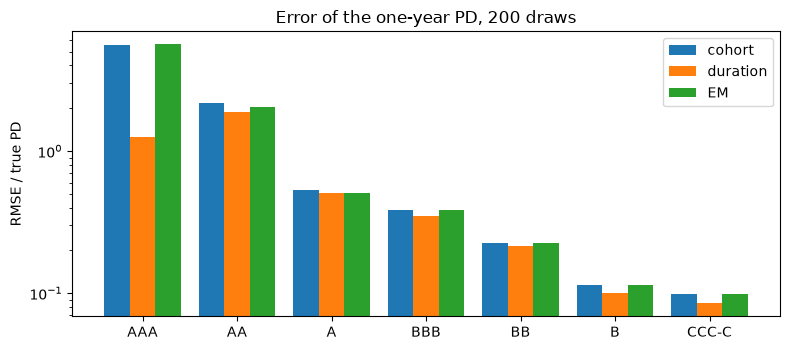

In [10]:
# Draw the relative RMSE of the cohort, duration and EM estimators by grade
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.27
for k, (name, color) in enumerate((("cohort", "tab:blue"), ("duration", "tab:orange"), ("em", "tab:green"))):
    rel = np.array(study[name]["rmse"]) / truth
    ax.bar(np.arange(7) + (k - 1) * width, rel, width, color=color, label={"cohort": "cohort", "duration": "duration", "em": "EM"}[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_ylabel("RMSE / true PD")
ax.set_title("Error of the one-year PD, 200 draws")
ax.legend()
fig.tight_layout()
plt.show()

### Step 8: a second agency

The same pooled estimator runs on any agency's cohorts. Fitch's transition page has a default category; Moody's has none, so no PD can be read off a Moody's matrix (the artifact carries `pd.d4` as empty for it). The next cell puts the long-run average PD of S&P and Fitch side by side, from the committed artifacts.

In [11]:
# Long-run average PD (definition d4) of S&P and Fitch, and the cohorts each agency contributes
lra_sp = np.array(sp["outputs"]["lra"]["d4"]["rate"], dtype=float)
lra_fitch = np.array(fitch["outputs"]["lra"]["d4"]["rate"], dtype=float)
print(f"{'grade':8s}{'S&P':>12s}{'Fitch':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{lra_sp[g]:12.5f}{lra_fitch[g]:12.5f}")
print("cohorts, S&P and Fitch:", sp["outputs"]["lra"]["d4"]["cohorts"][5], fitch["outputs"]["lra"]["d4"]["cohorts"][5])

grade            S&P       Fitch
AAA          0.00000     0.00000
AA           0.00005     0.00000
A            0.00030     0.00000
BBB          0.00079     0.00027
BB           0.00336     0.00147
B            0.01330     0.00491
CCC-C        0.08608     0.03649
cohorts, S&P and Fitch: 26 24


## Results

- **Pooling.** The 26 annual tables pool into a matrix equal to the committed one (largest difference 0.0). AAA rests on 1,895 pooled ratings and no default, AA on one default in 20,192, B on 372 defaults in 31,712.
- **A thin grade needs an interval.** The Wald interval of AAA has length zero, while the Agresti-Coull and Jeffreys intervals keep upper bounds of 0.244% and 0.132%. The engine's three intervals equal the committed ones for all seven grades.
- **Cohort against duration, on a known truth.** From one seeded dataset of 7,113 obligors and 10,953 stays, the cohort estimator reads 0 for AAA (the true one-year PD is 0.0066%) and the duration estimator 0.0204%. Over 200 draws the cohort estimate of AAA is exactly zero in 99% of them (AA: 83%) and the duration one never is; the duration estimator's error relative to the PD is 1.25 for AAA against 5.61 for the cohort estimator. From A to CCC-C the three estimators have similar relative errors, from about 0.5 at A to about 0.1 at B and CCC-C, so the choice matters where the data are thin.
- **EM does not recover AAA.** The EM generator of the snapshots has a relative error of 5.63 for AAA, the cohort estimator's, and never returns zero: it is always a valid generator, but it sees the same annual snapshots.
- **Aalen-Johansen** gives a matrix for any pair of dates with no homogeneity assumption and satisfies P(0, 2) = P(0, 1) P(1, 2) exactly. Its two single years differ because they are two samples of one chain.
- **Real counts.** EM on the 26 real S&P cohorts converges in 116 iterations to the committed generator (largest difference 0.0). Fitch's long-run average PDs are lower than S&P's in every grade from AA to CCC-C (B: 0.49% against 1.33%; CCC-C: 3.65% against 8.61%), over 24 cohorts against 26.

What this notebook does not show: whether the generator exists and which repair to use (notebook 03), whether the Markov assumption holds (notebook 04), or how the definition of default and the withdrawals bias a PD (notebook 10).

## Summary

- The cohort estimator pools annual snapshots and sees nothing that happens inside the year; the duration estimator uses every jump and the time in each grade; Aalen-Johansen drops time homogeneity; EM finds a valid generator from snapshots alone.
- On a thin grade the cohort estimator returns exactly zero most of the time and the Wald interval has width zero; the duration estimator and the Jeffreys interval do not.
- Estimators are compared on data whose truth is known, over many draws, never on one sample.
- Every recomputation is compared with the committed artifact after naming the engine version that baked it.

**What to try next.** Change the seed of the draw in Step 3 and watch the AAA estimates move; then read notebook 03 on the embedding problem.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Lando, D. and Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Aalen, O. O. and Johansen, S. (1978), An empirical transition matrix for non-homogeneous Markov chains based on censored observations, Scandinavian Journal of Statistics 5(3), 141-150.
- Bladt, M. and Sorensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), and Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627.